# 04 — Independent Component Analysis (ICA)

**NX-421 — Mini-project 1, Part 2 (Variant 2)**

In this notebook, we look for spatial patterns of brain activity in a data-driven way, without using the task design, and compare them with the GLM results of Part 1.

Following Lab 7, the data matrix $X$ (316 × voxels) has **one timepoint per row** (timepoints as samples, voxels as features). PCA first reduces the temporal dimension, and FastICA is then applied along the voxel dimension (**spatial ICA**), which yields spatially independent maps and their associated timecourses.

The notebook is organised as follows:

1. Data loading, brain mask and temporal preprocessing
2. PCA and scree plot
3. Choice of the number of components (stability analysis)
4. Final ICA model
5. Spatial maps of the components (axial view)
6. Correlation between the first 10 IC timecourses and the GLM regressors
7. Relation between timecourses and spatial maps
8. Sensitivity analysis

## 1. Data Loading and Preparation

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from IPython.display import display as show_table

from nilearn import datasets, image, masking, plotting
from scipy.ndimage import binary_erosion
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import PCA, FastICA
from sklearn.exceptions import ConvergenceWarning

# Project directories
PROJECT_ROOT = Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FUNC_DIR = OUTPUT_DIR / "functional"
GLM_DIR = OUTPUT_DIR / "glm"
ICA_DIR = OUTPUT_DIR / "ica"
FIG_DIR = ICA_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Inputs from Part 1
FMRI_PATH = FUNC_DIR / "tfMRI_LANGUAGE_LR_mcf_smooth.nii.gz"            # 02_functional_preprocessing
MASK_PATH = GLM_DIR / "first_level" / "epi_brain_mask.nii.gz"           # 03_glm
DESIGN_PATH = GLM_DIR / "design_matrix.csv"                             # 03_glm
GLM_Z_PATH = GLM_DIR / "first_level" / "story_minus_math" / "story_minus_math_z_score.nii.gz"

for path in [FMRI_PATH, MASK_PATH, DESIGN_PATH, GLM_Z_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing input: {path}. Run notebooks 02 and 03 first.")
    print("[OK]", path.relative_to(PROJECT_ROOT))

# Fixed analysis parameters
SEED = 42            # random seed of the final model, fixed a priori
TOL = 1e-4           # FastICA convergence tolerance (scikit-learn default)
MAX_ITER = 2000      # maximum number of FastICA iterations
Z_THRESHOLD = 2.5    # display threshold for the standardized spatial maps

[OK] outputs/functional/tfMRI_LANGUAGE_LR_mcf_smooth.nii.gz
[OK] outputs/glm/first_level/epi_brain_mask.nii.gz
[OK] outputs/glm/design_matrix.csv
[OK] outputs/glm/first_level/story_minus_math/story_minus_math_z_score.nii.gz


In [2]:
# Functional data, brain mask and GLM design matrix
fmri_img = nib.load(str(FMRI_PATH))
mask_img = nib.load(str(MASK_PATH))
mask_data = mask_img.get_fdata() > 0

n_volumes = fmri_img.shape[-1]
tr = float(fmri_img.header.get_zooms()[3])

assert mask_img.shape == fmri_img.shape[:3] and np.allclose(mask_img.affine, fmri_img.affine)

# Data matrix: one timepoint per row, one brain voxel per column
X = masking.apply_mask(fmri_img, mask_img).astype(np.float64)

glm_design = pd.read_csv(DESIGN_PATH, index_col=0).reset_index(drop=True)
assert len(glm_design) == n_volumes, "The design matrix and the fMRI run have different lengths."

print("fMRI:", fmri_img.shape, f"| TR = {tr:.2f} s")
print("Brain voxels:", int(mask_data.sum()))
print("Data matrix X (timepoints × voxels):", X.shape)
print("GLM regressors:", list(glm_design.columns))

fMRI: (91, 109, 91, 316) | TR = 0.72 s
Brain voxels: 207772
Data matrix X (timepoints × voxels): (316, 207772)
GLM regressors: ['cue', 'math', 'story', 'rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z', 'rot_x_deriv', 'rot_y_deriv', 'rot_z_deriv', 'trans_x_deriv', 'trans_y_deriv', 'trans_z_deriv', 'nonsteady_0', 'nonsteady_1', 'drift_1', 'drift_2', 'drift_3', 'constant']


### 1.1 Temporal Filtering and Standardization

Before PCA, we remove slow signal drifts from each voxel time series by regressing out the **same discrete cosine basis (high-pass cut-off 1/128 Hz) and constant as in the GLM design matrix** (Part 1). ICA and GLM are therefore applied to comparable data, and slow scanner drifts, which have a very large variance, do not dominate the decomposition. The task blocks (story–math cycle of about 40–55 s) are well above the 128 s cut-off period, so the task signal is preserved.

Each voxel time series is then z-scored (zero mean, unit variance), so that voxels with a high raw intensity do not dominate the PCA.

In [3]:
# Drift basis of the GLM (cosine regressors + constant)
drift_cols = [c for c in glm_design.columns if c.startswith("drift")]
D = np.column_stack([glm_design[drift_cols].to_numpy(), np.ones(n_volumes)])

# Remove the drifts from every voxel time series (least-squares projection)
X_filtered = X - D @ np.linalg.lstsq(D, X, rcond=None)[0]

# Z-score each voxel time series
voxel_std = X_filtered.std(axis=0)
X_std = (X_filtered - X_filtered.mean(axis=0)) / np.where(voxel_std > 0, voxel_std, 1.0)
X_std = X_std.astype(np.float32)
del X, X_filtered

print("Regressed-out drift terms:", drift_cols + ["constant"])
print("Standardized data:", X_std.shape,
      f"| mean = {X_std.mean():.4f} | std = {X_std.std():.4f}")

Regressed-out drift terms: ['drift_1', 'drift_2', 'drift_3', 'constant']
Standardized data: (316, 207772) | mean = -0.0000 | std = 1.0000


## 2. Dimensionality Reduction (PCA)

PCA is applied with timepoints as samples and voxels as features. Its spatial components (`pca.components_`, voxels) form an orthonormal basis of the main spatial patterns, and its scores (`X_pca`, time) give their timecourses. The scree plot (variance per component) is used to locate the elbow, and the cumulative curve reports the total variance retained.

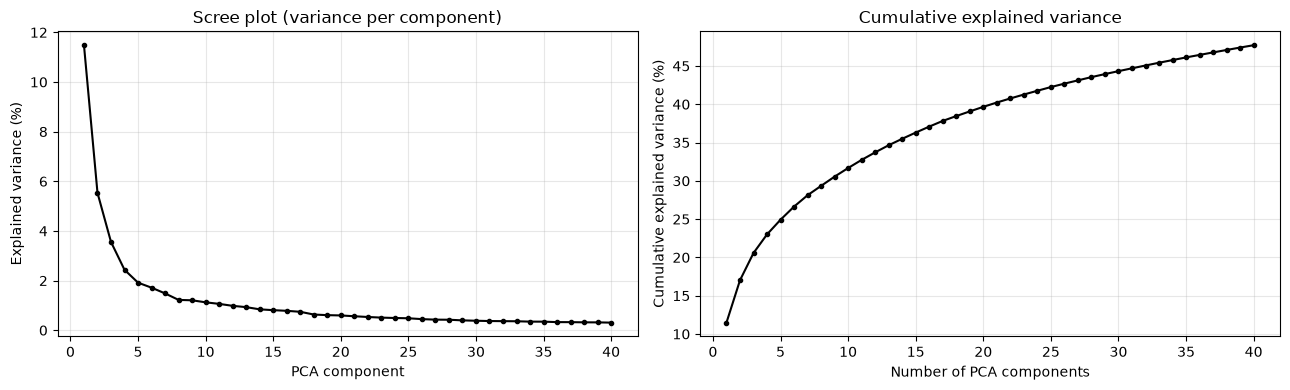

10 components: 31.7% of the variance
15 components: 36.3% of the variance
20 components: 39.7% of the variance
25 components: 42.2% of the variance
30 components: 44.3% of the variance
40 components: 47.7% of the variance


In [4]:
N_PCA_MAX = 40
pca = PCA(n_components=N_PCA_MAX, svd_solver="randomized", random_state=SEED)
X_pca = pca.fit_transform(X_std)                       # (timepoints, components)

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(np.arange(1, N_PCA_MAX + 1), explained * 100, marker=".", c="k")
axes[0].set(xlabel="PCA component", ylabel="Explained variance (%)",
            title="Scree plot (variance per component)")
axes[1].plot(np.arange(1, N_PCA_MAX + 1), cumulative * 100, marker=".", c="k")
axes[1].set(xlabel="Number of PCA components", ylabel="Cumulative explained variance (%)",
            title="Cumulative explained variance")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIG_DIR / "fig_pca_variance.png", dpi=300, bbox_inches="tight")
plt.show()

for k in [10, 15, 20, 25, 30, 40]:
    print(f"{k:2d} components: {cumulative[k - 1] * 100:.1f}% of the variance")

## 3. Choice of the Number of Components

The number of components is chosen **without using the task regressors**, from two criteria:

- **Scree plot:** the model order must be above the elbow, where the variance per component stops decreasing steeply.
- **Stability across random initialisations:** for each candidate model order $k$ (with $N_{PCA} = N_{ICA} = k$), FastICA is run with the reference seed and 5 other seeds. Each component of the reference run is matched one-to-one to its most similar component in every other run (absolute spatial correlation, Hungarian assignment), and a component is considered **stable** if its median matched correlation is above 0.9.

We use $N_{ICA} = N_{PCA}$: the PCA spatial components are orthonormal and all have the same variance, so a further reduction inside FastICA's whitening step would be ill-defined (such configurations did not converge in preliminary tests). The dimensionality reduction is therefore performed by PCA only.

**Selection rule (fixed before looking at the task correlations):** candidates are taken above the elbow of the scree plot (k = 10, 15, 20, 25, 30). k is increased as long as **at least 90 % of the components are stable and all runs converge**; we retain the last model order before the first one that fails this criterion.

In [5]:
def fit_spatial_ica(k, seed):
    # Spatial ICA on the first k PCA spatial components (voxels are the observations)
    model = FastICA(n_components=k, whiten="unit-variance", algorithm="parallel",
                    random_state=seed, max_iter=MAX_ITER, tol=TOL)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        maps = model.fit_transform(pca.components_[:k].T)      # (voxels, k)
    converged = model.n_iter_ < MAX_ITER and np.isfinite(maps).all()
    return model, maps, converged


def abs_spatial_corr(A, B):
    # |Pearson correlation| between the columns of A and the columns of B
    A = (A - A.mean(0)) / A.std(0)
    B = (B - B.mean(0)) / B.std(0)
    return np.abs(A.T @ B) / A.shape[0]


CANDIDATES = [10, 15, 20, 25, 30]
OTHER_SEEDS = [0, 1, 7, 21, 99]

# The stability analysis is computed once on the filtered data and cached
# (delete this file to recompute it, e.g. after changing the preprocessing)
STAB_PATH = ICA_DIR / "ica_model_order_stability_filtered.csv"

stability_rows = []
for k in ([] if STAB_PATH.exists() else CANDIDATES):
    _, ref_maps, ref_conv = fit_spatial_ica(k, SEED)
    matched, n_conv = [], int(ref_conv)
    for s in OTHER_SEEDS:
        _, maps, conv = fit_spatial_ica(k, s)
        n_conv += int(conv)
        C = abs_spatial_corr(ref_maps, maps)
        rows, cols = linear_sum_assignment(-C)              # one-to-one matching
        matched.append(C[rows, cols])
    comp_stability = np.median(matched, axis=0)
    stability_rows.append({
        "k (N_PCA = N_ICA)": k,
        "PCA variance (%)": round(cumulative[k - 1] * 100, 1),
        "Median stability |r|": round(float(np.median(comp_stability)), 3),
        "Stable components (%)": round(100 * float(np.mean(comp_stability > 0.9)), 1),
        "Converged runs": n_conv,
        "Total runs": 1 + len(OTHER_SEEDS),
    })
    print(f"k = {k} done")

if STAB_PATH.exists():
    stability_table = pd.read_csv(STAB_PATH)
    print("Loaded cached results:", STAB_PATH.name)
else:
    stability_table = pd.DataFrame(stability_rows)
    stability_table.to_csv(STAB_PATH, index=False)
stability_table.to_csv(ICA_DIR / "ica_model_order_stability.csv", index=False)
show_table(stability_table)

Loaded cached results: ica_model_order_stability_filtered.csv


,k (N_PCA = N_ICA),PCA variance (%),Median stability |r|,Stable components (%),Converged runs,Total runs
0,10,31.7,1.000,100.0,6,6
1,15,36.3,0.999,100.0,6,6
2,20,39.7,0.990,65.0,6,6
3,25,42.2,0.989,88.0,6,6
4,30,44.3,1.000,100.0,6,6


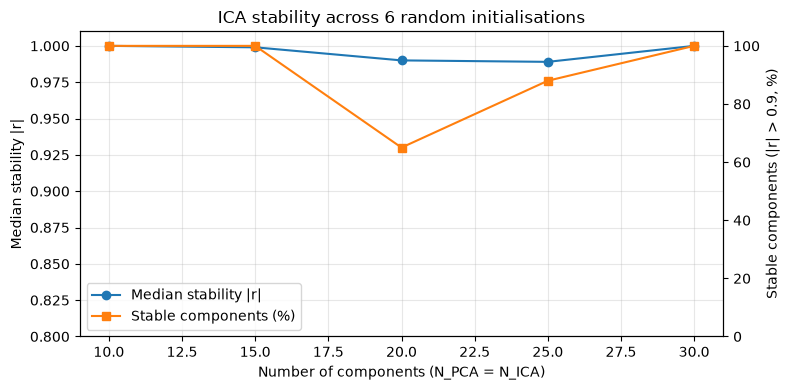

Selected number of components: N_PCA = N_ICA = 15 (36.3% of the variance)


In [6]:
# Stability as a function of the model order
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(stability_table["k (N_PCA = N_ICA)"], stability_table["Median stability |r|"],
         marker="o", c="tab:blue", label="Median stability |r|")
ax1.set(xlabel="Number of components (N_PCA = N_ICA)", ylabel="Median stability |r|",
        ylim=(0.8, 1.01))
ax2 = ax1.twinx()
ax2.plot(stability_table["k (N_PCA = N_ICA)"], stability_table["Stable components (%)"],
         marker="s", c="tab:orange", label="Stable components (%)")
ax2.set(ylabel="Stable components (|r| > 0.9, %)", ylim=(0, 105))
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [l.get_label() for l in lines], loc="lower left")
ax1.set_title("ICA stability across 6 random initialisations")
ax1.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIG_DIR / "fig_ica_stability.png", dpi=300, bbox_inches="tight")
plt.show()

# Selection rule: increase k as long as >= 90 % of the components are stable
# and all runs converged; stop at the first model order that fails
passes = ((stability_table["Stable components (%)"] >= 90)
          & (stability_table["Converged runs"] == stability_table["Total runs"])).to_numpy()
ks = stability_table["k (N_PCA = N_ICA)"].to_numpy()
n_pass = len(passes) if passes.all() else int(np.argmin(passes))
N_FINAL = int(ks[n_pass - 1]) if n_pass > 0 else int(ks[0])
print(f"Selected number of components: N_PCA = N_ICA = {N_FINAL} "
      f"({cumulative[N_FINAL - 1] * 100:.1f}% of the variance)")

### 3.1 Selected Number of Components

The scree plot drops steeply over the first ~5 components and flattens after ~8–10 components. All model orders converged in 6/6 runs. 100 % of the components were stable for k = 10 and k = 15, but only 65 % at k = 20, the first model order failing the criterion. Following the pre-defined rule, we retain **k = 15** components (N_PCA = N_ICA = 15, 36.3 % of the variance). Stability was not monotonic (88 % at k = 25, 100 % at k = 30), which is why the rule stops at the first failure instead of taking the largest passing k.

## 4. Final ICA Model

The final model is fitted with the selected number of components and the seed fixed a priori. Because the sign of an independent component is arbitrary, each component is oriented so that its largest absolute spatial weight is positive; the timecourse is flipped accordingly, so that the reconstruction of the data is unchanged.

The timecourses are obtained by projecting the PCA scores on the ICA mixing matrix: since $X_c \approx X_{PCA} P$ and $P^\top \approx S A^\top$, we have $X_c \approx (X_{PCA} A)\, S^\top$, i.e. the timecourses are $X_{PCA} A$.

In [7]:
final_model, final_maps, final_converged = fit_spatial_ica(N_FINAL, SEED)
final_tc = X_pca[:, :N_FINAL] @ final_model.mixing_          # (timepoints, N_FINAL)
print(f"Iterations: {final_model.n_iter_} | converged: {final_converged}")

# Sign convention: largest absolute spatial weight positive
peak_signs = np.sign(final_maps[np.abs(final_maps).argmax(axis=0), np.arange(N_FINAL)])
final_maps = final_maps * peak_signs
final_tc = final_tc * peak_signs

# Standardized maps (for display and thresholding)
final_maps_z = (final_maps - final_maps.mean(0)) / final_maps.std(0)

ic_names = [f"IC{i + 1:02d}" for i in range(N_FINAL)]
pd.DataFrame(final_tc, columns=ic_names).to_csv(ICA_DIR / "ica_timecourses.csv", index=False)
for i, name in enumerate(ic_names):
    masking.unmask(final_maps_z[:, i], mask_img).to_filename(str(ICA_DIR / f"ica_{name}.nii.gz"))
print(f"{N_FINAL} spatial maps and timecourses saved in", ICA_DIR.relative_to(PROJECT_ROOT))

Iterations: 30 | converged: True
15 spatial maps and timecourses saved in outputs/ica


## 5. Spatial Maps of the Independent Components

Each component is displayed separately in axial view, on the MNI152 template (the data are in MNI space). The maps are standardized (z-scored across voxels) and thresholded at |z| > 2.5 for display; these values are not statistical tests.

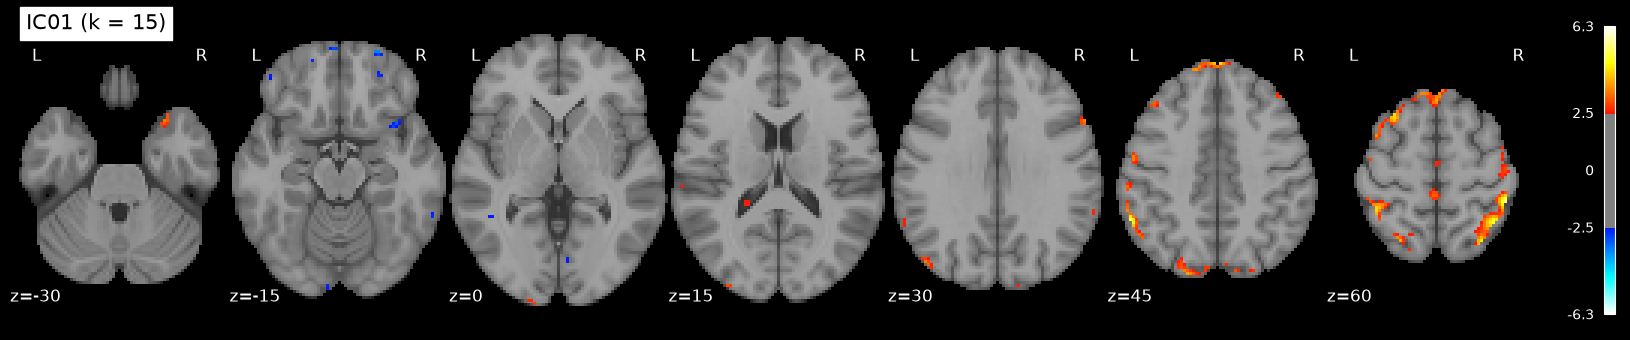

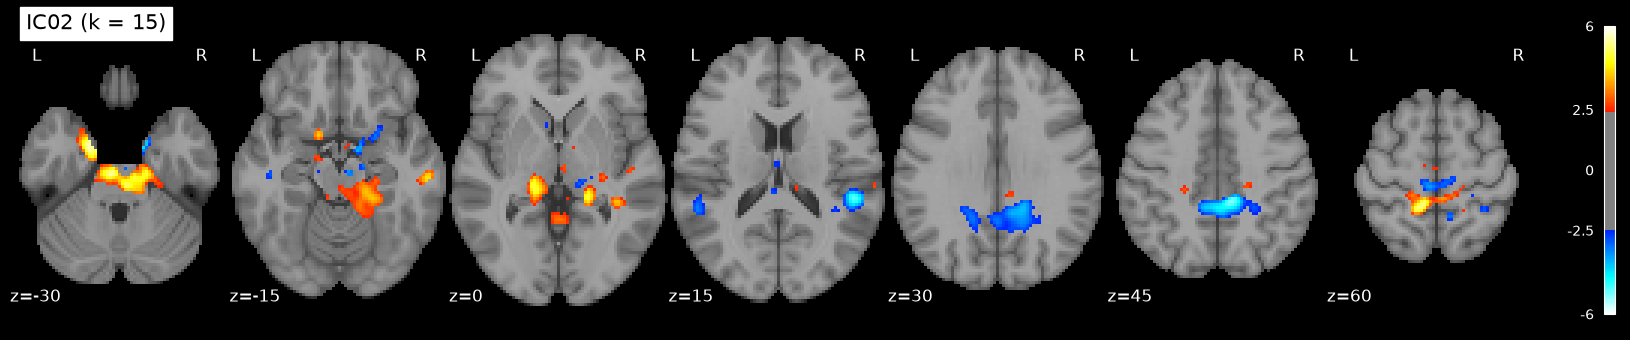

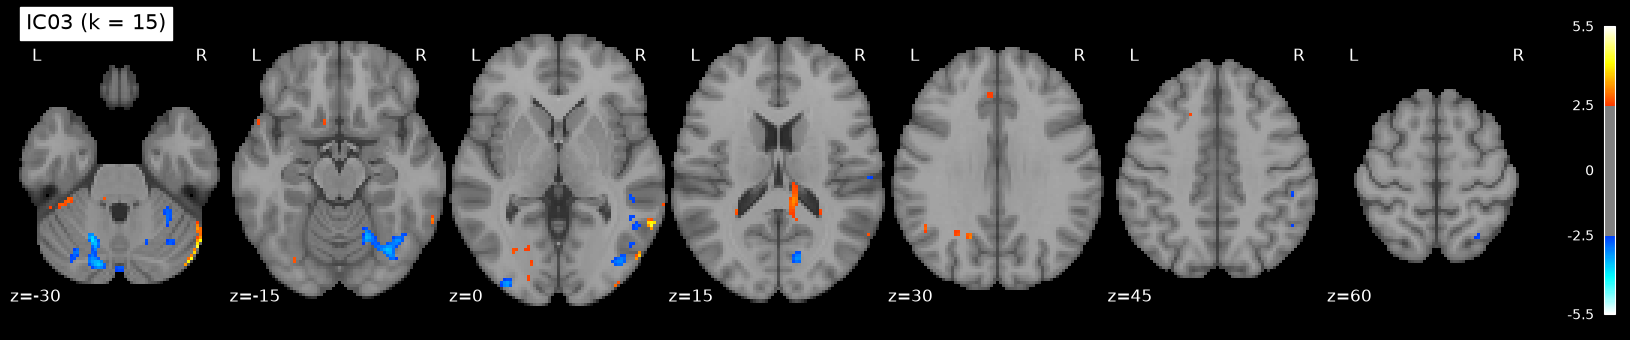

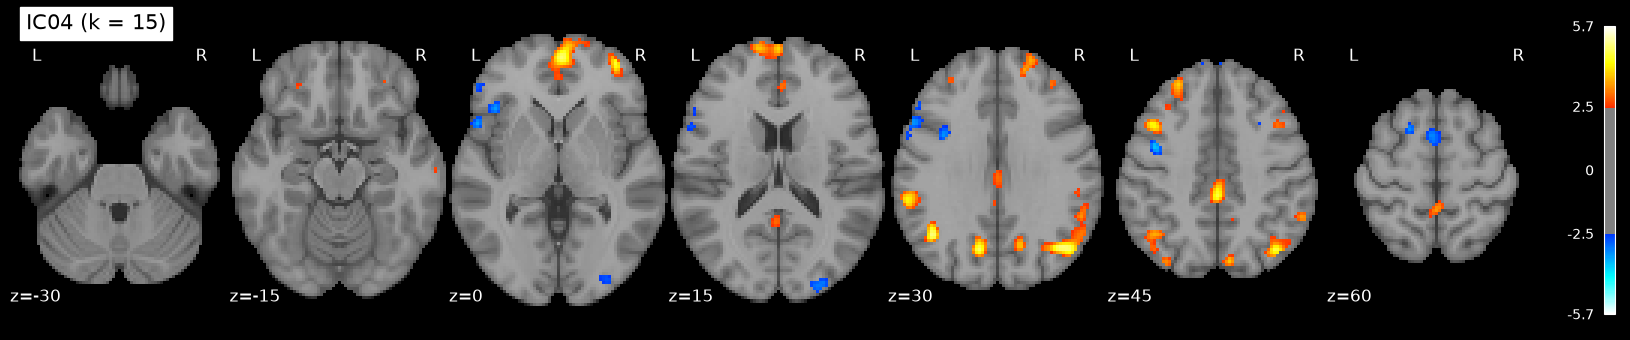

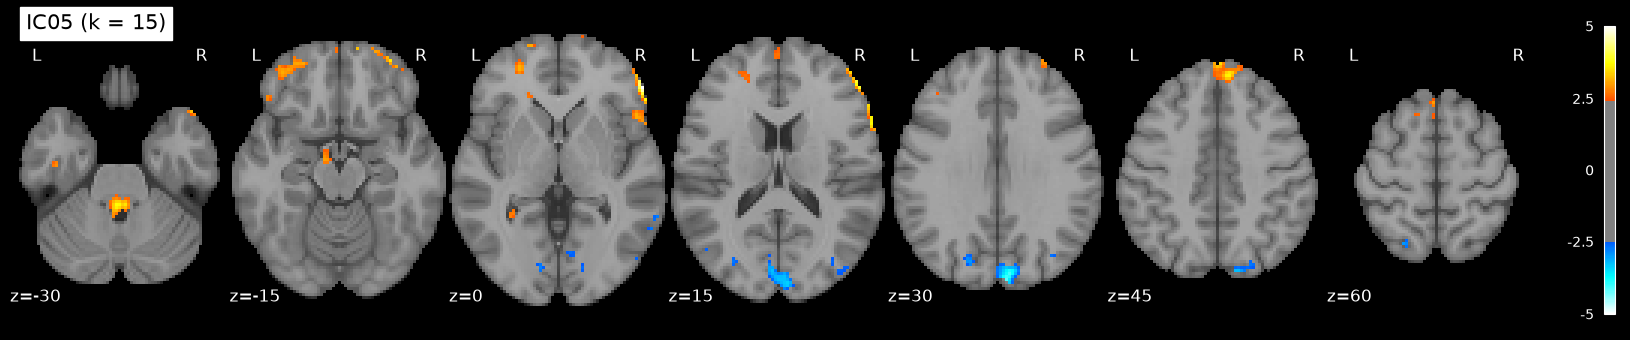

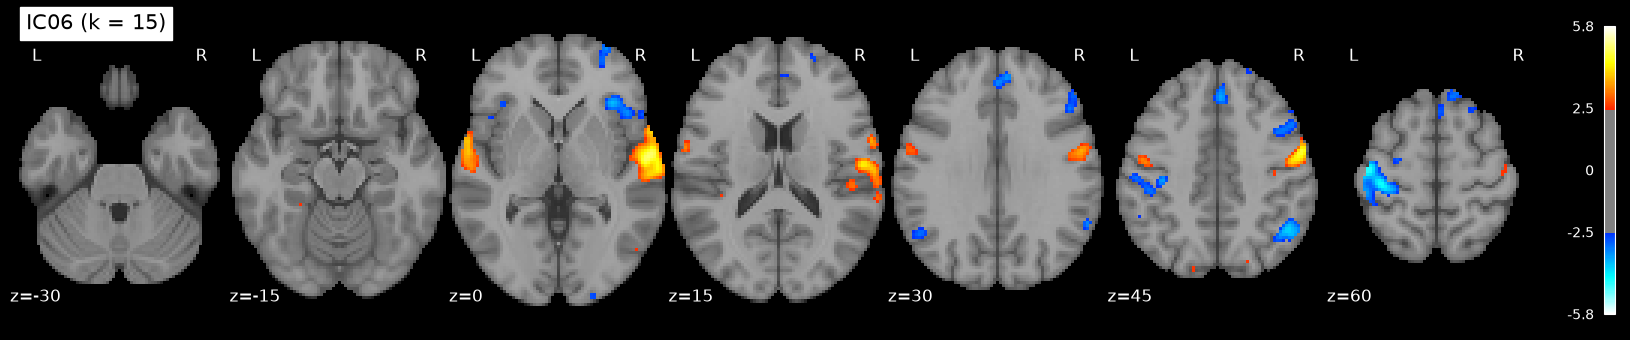

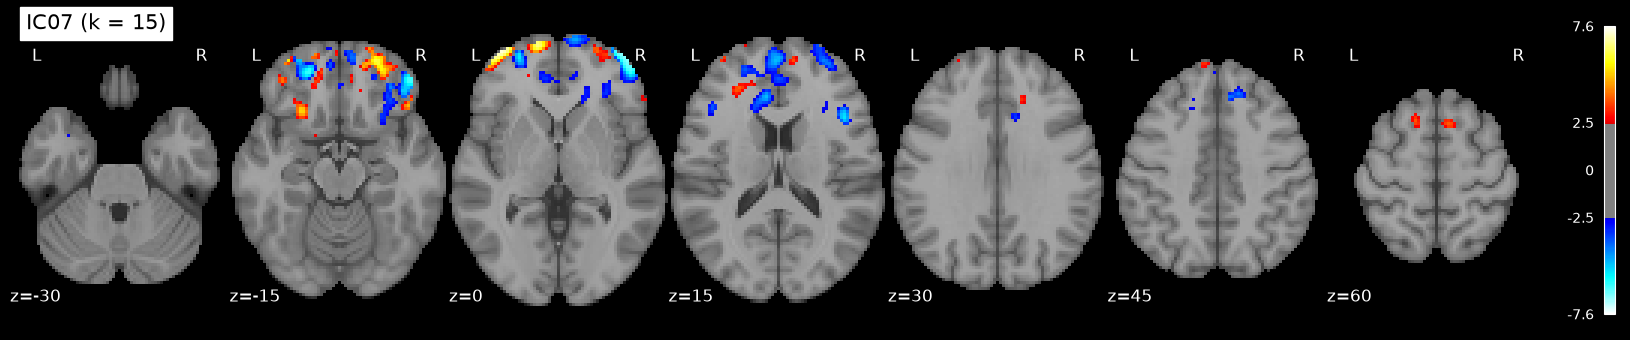

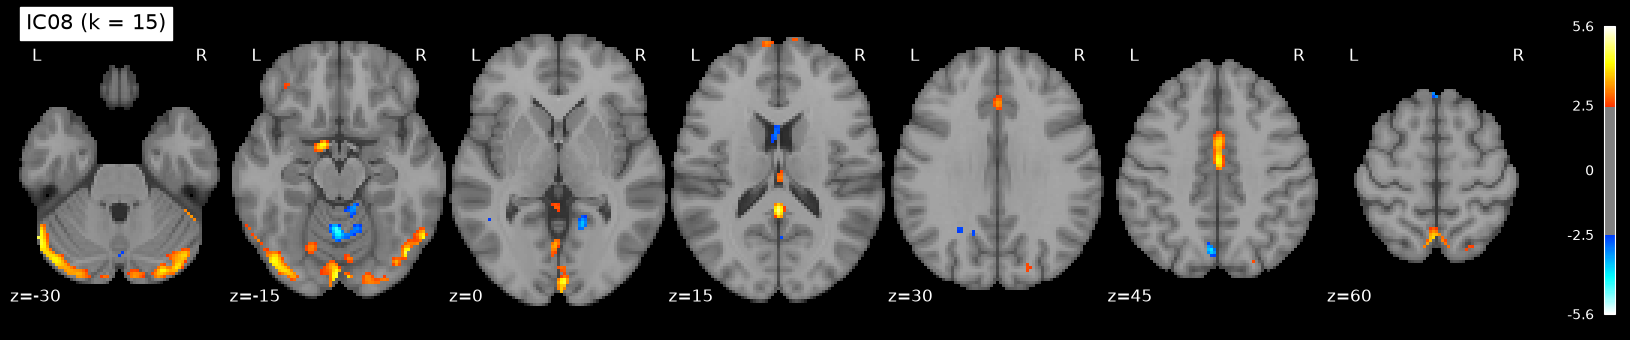

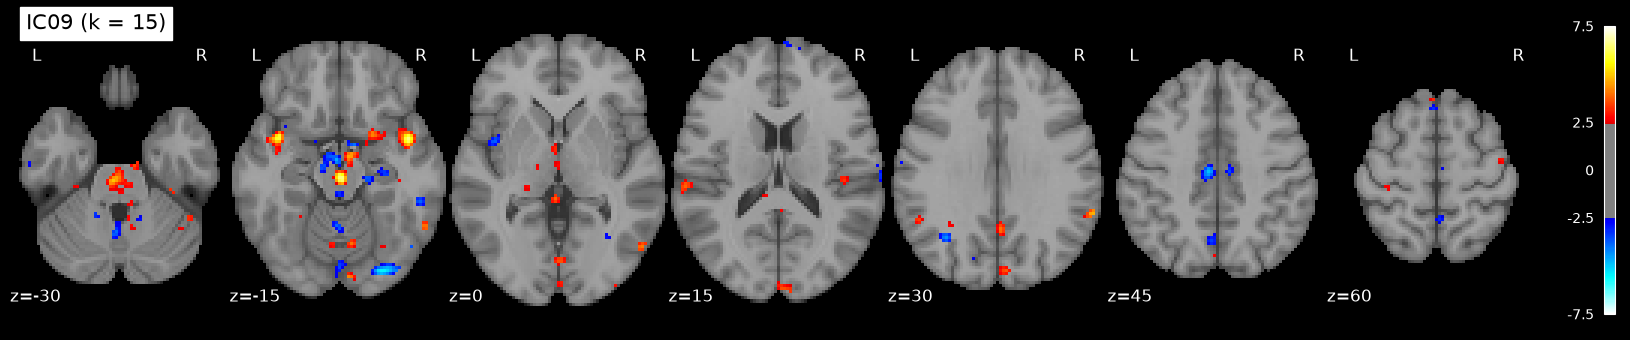

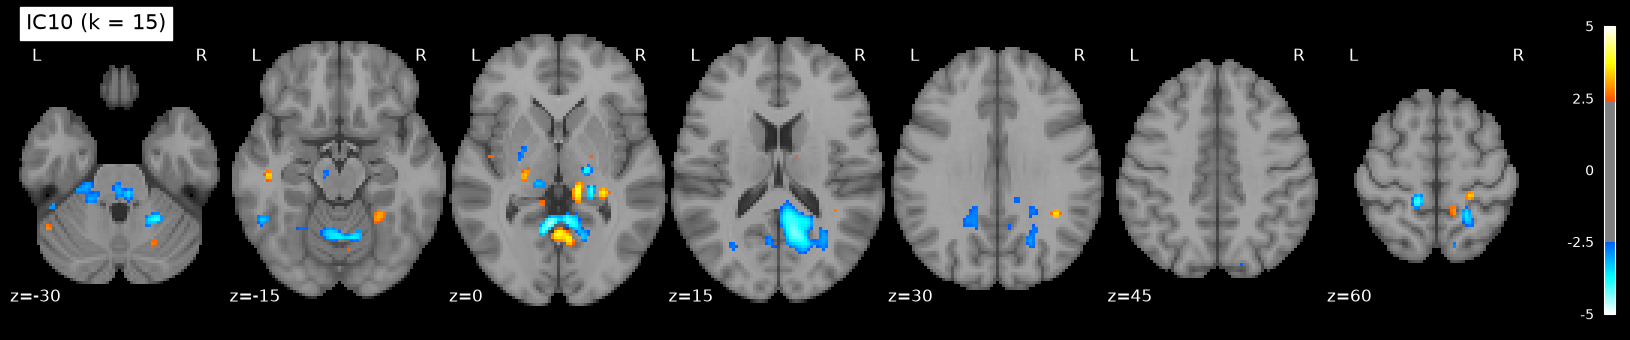

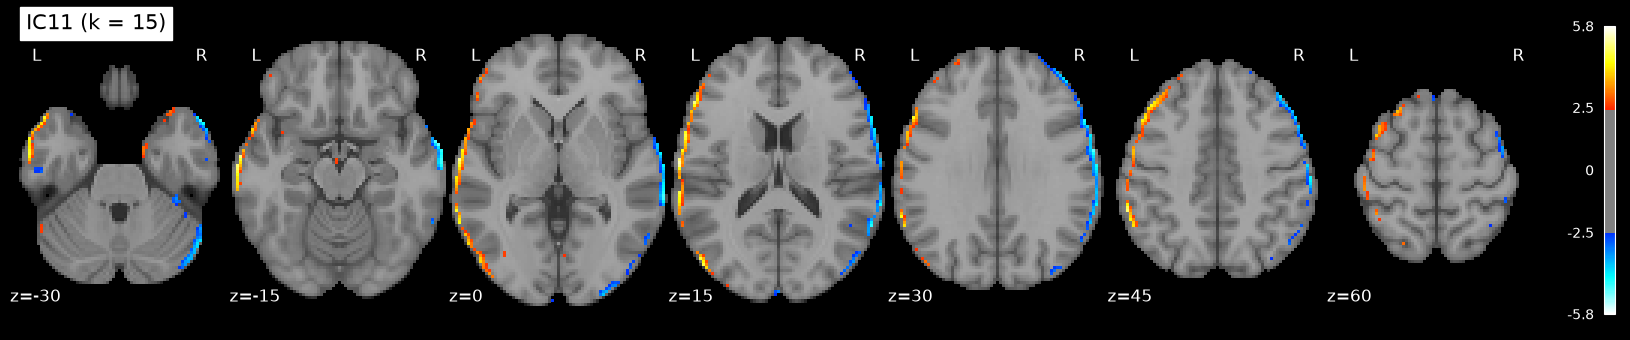

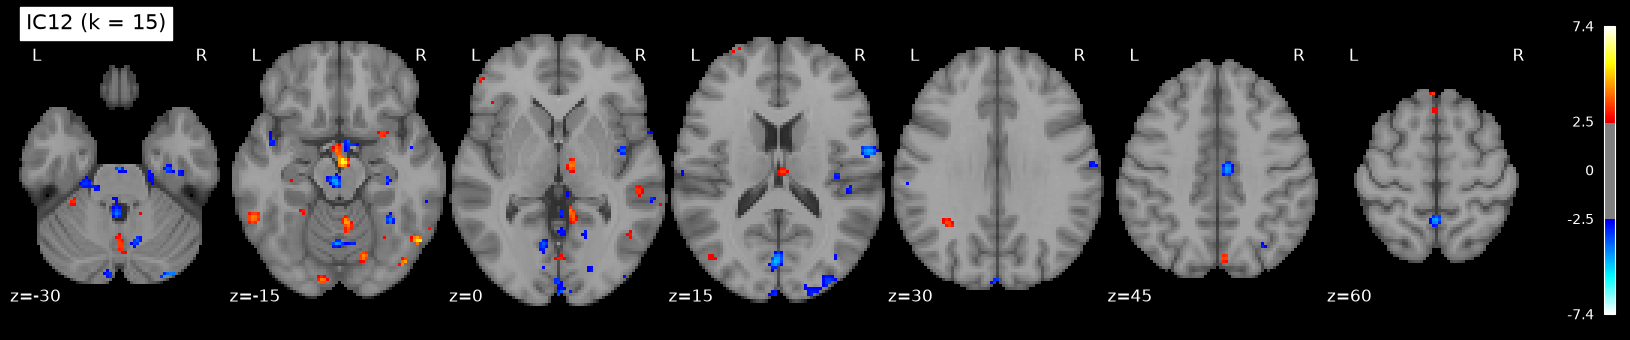

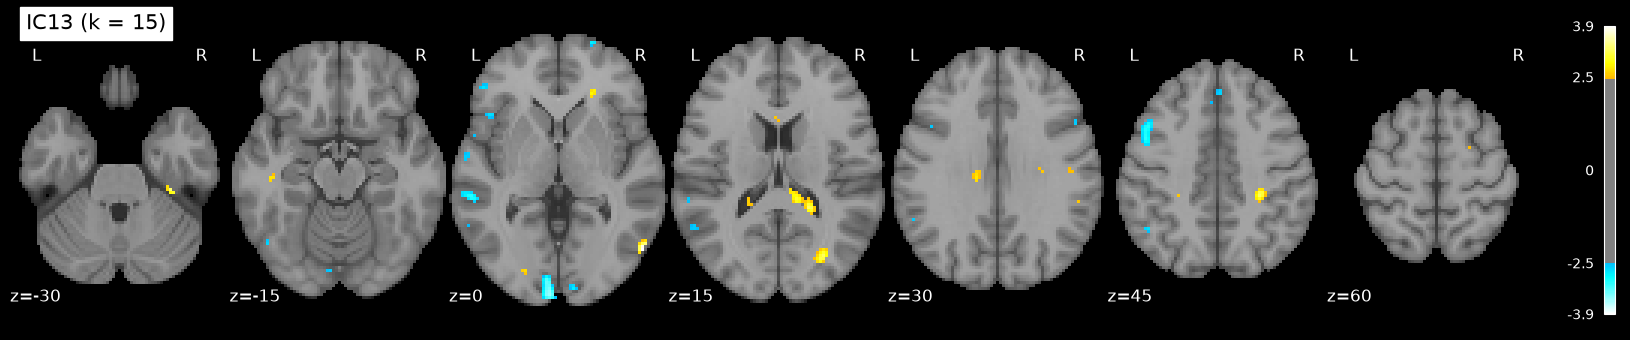

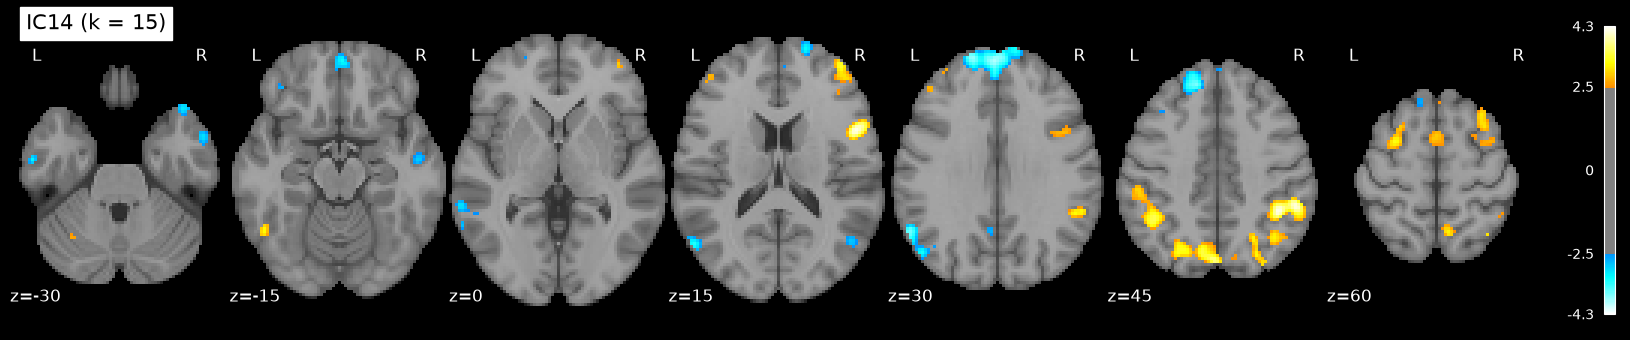

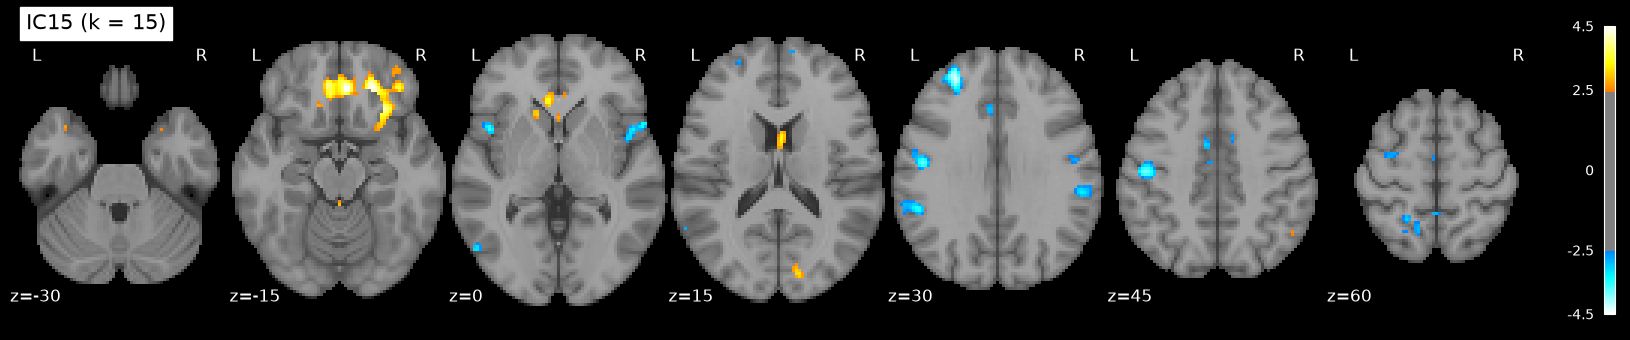

In [8]:
mni_template = datasets.load_mni152_template(resolution=2)

for i, name in enumerate(ic_names):
    comp_img = masking.unmask(final_maps_z[:, i], mask_img)
    disp = plotting.plot_stat_map(
        comp_img, bg_img=mni_template, display_mode="z",
        cut_coords=[-30, -15, 0, 15, 30, 45, 60], threshold=Z_THRESHOLD,
        cmap="cold_hot", colorbar=True, title=f"{name} (k = {N_FINAL})")
    disp.savefig(str(FIG_DIR / f"ica_{name}_axial.png"), dpi=200)
    plotting.show()

## 6. Correlation Between the IC Timecourses and the GLM Regressors

We compute the Pearson correlation between the timecourses of the **first 10 components, in the order returned by FastICA**, and the regressors of the GLM design matrix of Part 1: the task regressors (story, math, cue), the six motion parameters and their derivatives, and the cosine drift regressors. The constant and the two spike regressors are not informative here and are excluded.

Note that FastICA returns the components in an arbitrary order, which depends on the random initialisation; the seed was fixed a priori and the returned order was kept, as required.

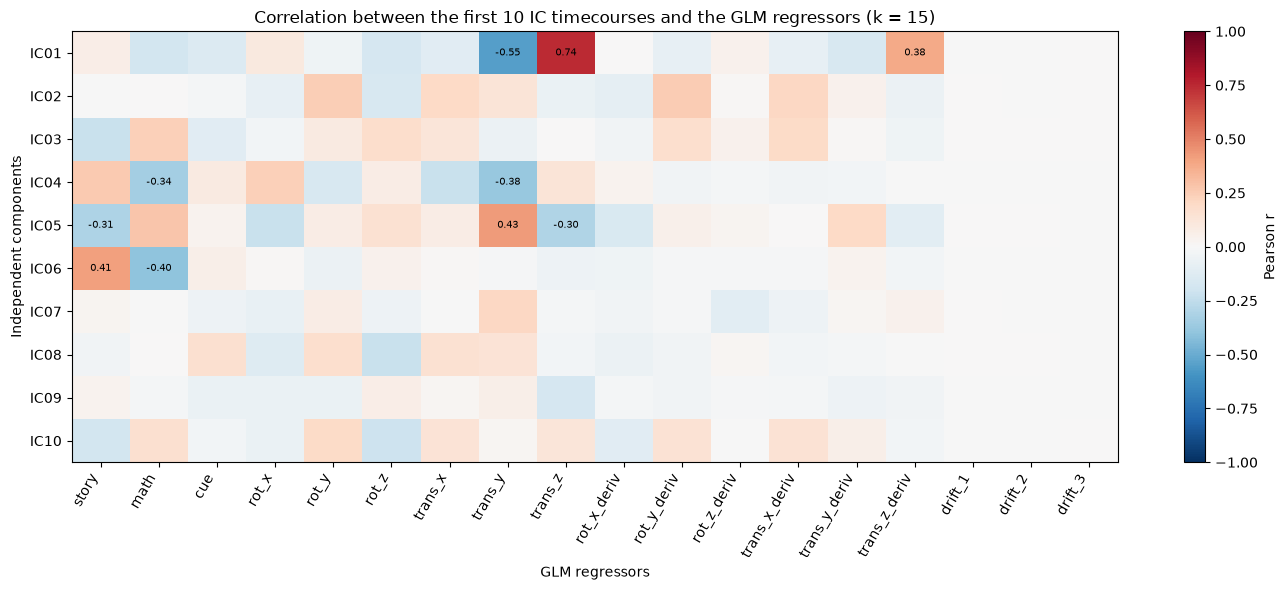

In [9]:
selected_regressors = (["story", "math", "cue"]
                       + [c for c in glm_design.columns if c.startswith(("rot_", "trans_"))]
                       + [c for c in glm_design.columns if c.startswith("drift")])
n_corr = min(10, N_FINAL)

corr_values = np.array([[np.corrcoef(final_tc[:, i], glm_design[c].to_numpy())[0, 1]
                         for c in selected_regressors] for i in range(n_corr)])
ica_glm_corr = pd.DataFrame(corr_values, index=ic_names[:n_corr], columns=selected_regressors)
ica_glm_corr.to_csv(ICA_DIR / "ica_glm_correlations.csv")

fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(corr_values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
for i in range(corr_values.shape[0]):
    for j in range(corr_values.shape[1]):
        if abs(corr_values[i, j]) >= 0.3:
            ax.text(j, i, f"{corr_values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_xticks(range(len(selected_regressors)))
ax.set_xticklabels(selected_regressors, rotation=60, ha="right")
ax.set_yticks(range(n_corr))
ax.set_yticklabels(ic_names[:n_corr])
ax.set(title=f"Correlation between the first {n_corr} IC timecourses and the GLM regressors (k = {N_FINAL})",
       xlabel="GLM regressors", ylabel="Independent components")
fig.colorbar(im, ax=ax, label="Pearson r")
plt.tight_layout()
fig.savefig(FIG_DIR / "fig_ica_glm_correlations.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Relation Between Timecourses and Spatial Maps

To relate each timecourse to its spatial map, we summarise for each of the first 10 components:

- its correlation with the task regressors, the motion parameters (maximum |r|) and the slowest drift regressor;
- the **spatial correlation** of its map with the unthresholded Story − Math GLM Z-map;
- the percentage of its suprathreshold voxels (|z| > 2.5) located on the outer layer of the brain mask (a typical signature of motion or edge artefacts);
- the Yeo 7-network (from the Schaefer et al. 2018 atlas, as in Part 1) containing most of its positive and negative suprathreshold voxels.

In [10]:
# Unthresholded Story - Math GLM Z-map, in the same voxel order as the ICA maps
glm_z_values = masking.apply_mask(nib.load(str(GLM_Z_PATH)), mask_img)

# Outer layer of the brain mask (2 voxels)
edge_vox = (mask_data & ~binary_erosion(mask_data, iterations=2))[mask_data]

# Yeo 7 networks from the Schaefer 2018 atlas (cached by 03_glm)
YEO7 = {1: "Visual", 2: "Somatomotor", 3: "Dorsal attention", 4: "Ventral attention",
        5: "Limbic", 6: "Frontoparietal", 7: "Default mode"}
try:
    schaefer = datasets.fetch_atlas_schaefer_2018(n_rois=400, yeo_networks=7, resolution_mm=2)
    schaefer_img = image.load_img(schaefer.maps)
    labels = [l.decode() if isinstance(l, bytes) else str(l) for l in schaefer.labels]
    labels = [l for l in labels if l != "Background"]
    keys = {"_Vis_": 1, "_SomMot_": 2, "_DorsAttn_": 3, "_SalVentAttn_": 4,
            "_Limbic_": 5, "_Cont_": 6, "_Default_": 7}
    parcels = np.rint(schaefer_img.get_fdata()).astype(int)
    yeo_3d = np.zeros_like(parcels)
    for value, label in enumerate(labels, start=1):
        yeo_3d[parcels == value] = next(v for k, v in keys.items() if k in label)
    yeo_img = image.resample_to_img(image.new_img_like(schaefer_img, yeo_3d.astype(np.int32)),
                                    mask_img, interpolation="nearest")
    yeo_vox = np.rint(masking.apply_mask(yeo_img, mask_img)).astype(int)
except Exception as err:
    print("Yeo atlas not available:", err)
    yeo_vox = None


def dominant_network(selection):
    # Yeo network containing most of the selected voxels (with its percentage)
    if yeo_vox is None or selection.sum() == 0:
        return "—"
    labels_sel = yeo_vox[selection]
    counts = np.bincount(labels_sel, minlength=8)[1:]
    if counts.sum() == 0:
        return "outside cortex"
    best = int(counts.argmax()) + 1
    return f"{YEO7[best]} ({100 * counts.max() / selection.sum():.0f}%)"


motion_cols = [c for c in selected_regressors if c.startswith(("rot_", "trans_"))]
summary_rows = []
for i in range(n_corr):
    z = final_maps_z[:, i]
    supra = np.abs(z) > Z_THRESHOLD
    summary_rows.append({
        "IC": ic_names[i],
        "r story": ica_glm_corr.loc[ic_names[i], "story"],
        "r math": ica_glm_corr.loc[ic_names[i], "math"],
        "r cue": ica_glm_corr.loc[ic_names[i], "cue"],
        "max |r| motion": ica_glm_corr.loc[ic_names[i], motion_cols].abs().max(),
        "r drift_1": ica_glm_corr.loc[ic_names[i], "drift_1"],
        "spatial r with GLM": np.corrcoef(final_maps[:, i], glm_z_values)[0, 1],
        "% voxels at edge": 100 * (supra & edge_vox).sum() / max(supra.sum(), 1),
        "positive network": dominant_network(z > Z_THRESHOLD),
        "negative network": dominant_network(z < -Z_THRESHOLD),
    })

ic_summary = pd.DataFrame(summary_rows).set_index("IC").round(2)
ic_summary.to_csv(ICA_DIR / "ica_component_summary.csv")
print(f"The edge layer contains {100 * edge_vox.mean():.1f}% of the brain-mask voxels.")
show_table(ic_summary)

The edge layer contains 15.0% of the brain-mask voxels.


,r story,r math,r cue,max |r| motion,r drift_1,spatial r with GLM,% voxels at edge,positive network,negative network
IC,,,,,,,,,
IC01,0.07,-0.18,-0.14,0.74,-0.0,0.07,77.83,Somatomotor (32%),Default mode (8%)
IC02,-0.00,0.00,-0.02,0.25,0.0,0.03,9.51,Limbic (11%),Default mode (27%)
IC03,-0.22,0.24,-0.11,0.19,0.0,-0.16,13.71,Visual (15%),Visual (21%)
IC04,0.26,-0.34,0.09,0.38,-0.0,0.15,19.72,Default mode (53%),Default mode (33%)
IC05,-0.31,0.27,0.04,0.43,0.0,-0.09,45.91,Default mode (25%),Visual (72%)
IC06,0.41,-0.40,0.06,0.06,-0.0,0.30,27.01,Somatomotor (80%),Somatomotor (30%)
IC07,0.02,-0.00,-0.05,0.21,0.0,0.08,27.28,Frontoparietal (33%),Default mode (37%)
IC08,-0.04,0.01,0.16,0.23,0.0,0.02,33.79,Visual (23%),Visual (15%)
IC09,0.04,-0.02,-0.07,0.17,-0.0,0.05,24.94,Visual (15%),Visual (10%)


### 7.1 Task-Related Component

We display the component (among all components) whose timecourse is most correlated with the story regressor, next to the Story − Math GLM map, together with its timecourse and the (story − math) GLM regressor.

Most task-related component: IC14 (position 14/15) | r story = -0.77, r math = 0.74, spatial r with GLM = -0.80


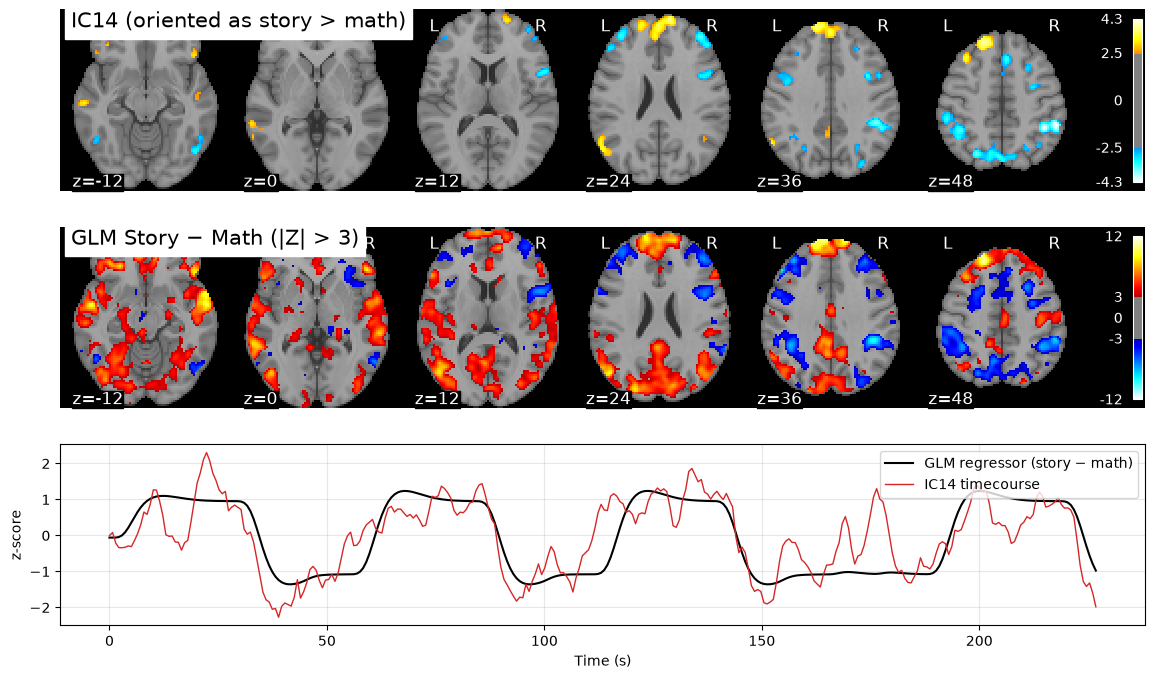

In [11]:
# Search the task-related component among ALL components (not only the first 10)
r_story_all = np.array([np.corrcoef(final_tc[:, i], glm_design["story"])[0, 1] for i in range(N_FINAL)])
r_math_all = np.array([np.corrcoef(final_tc[:, i], glm_design["math"])[0, 1] for i in range(N_FINAL)])
task_idx = int(np.abs(r_story_all).argmax())
task_name = ic_names[task_idx]
sign = np.sign(r_story_all[task_idx])   # orient the component as "story > math"

print(f"Most task-related component: {task_name} (position {task_idx + 1}/{N_FINAL}) | "
      f"r story = {r_story_all[task_idx]:.2f}, r math = {r_math_all[task_idx]:.2f}, "
      f"spatial r with GLM = {np.corrcoef(final_maps[:, task_idx], glm_z_values)[0, 1]:.2f}")

fig = plt.figure(figsize=(14, 8))
ax_ic = fig.add_subplot(3, 1, 1)
ax_glm = fig.add_subplot(3, 1, 2)
ax_tc = fig.add_subplot(3, 1, 3)
cuts = [-12, 0, 12, 24, 36, 48]

plotting.plot_stat_map(masking.unmask(sign * final_maps_z[:, task_idx], mask_img),
                       bg_img=mni_template, display_mode="z", cut_coords=cuts,
                       threshold=Z_THRESHOLD, cmap="cold_hot", axes=ax_ic,
                       title=f"{task_name} (oriented as story > math)")
plotting.plot_stat_map(str(GLM_Z_PATH), bg_img=mni_template, display_mode="z",
                       cut_coords=cuts, threshold=3.0, cmap="cold_hot", axes=ax_glm,
                       title="GLM Story − Math (|Z| > 3)")

frame_times = np.arange(n_volumes) * tr
task_regressor = (glm_design["story"] - glm_design["math"]).to_numpy()
zs = lambda v: (v - v.mean()) / v.std()
ax_tc.plot(frame_times, zs(task_regressor), c="k", lw=1.5, label="GLM regressor (story − math)")
ax_tc.plot(frame_times, zs(sign * final_tc[:, task_idx]), c="tab:red", lw=1,
           label=f"{task_name} timecourse")
ax_tc.set(xlabel="Time (s)", ylabel="z-score")
ax_tc.legend(loc="upper right")
ax_tc.grid(alpha=0.3)
fig.savefig(FIG_DIR / "fig_task_component_vs_glm.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Sensitivity Analysis

To check that the conclusions do not depend on the exact model order, we repeat the decomposition with the other candidate orders and report, for each, the component (among all components) most correlated with the story regressor, its position in the order returned by FastICA, and the spatial correlation of its map with the Story − Math GLM map.

In [12]:
sensitivity_rows = []
for k in CANDIDATES:
    model, maps, conv = fit_spatial_ica(k, SEED)
    tc = X_pca[:, :k] @ model.mixing_
    r_story = np.array([np.corrcoef(tc[:, i], glm_design["story"])[0, 1] for i in range(k)])
    best = int(np.abs(r_story).argmax())
    sensitivity_rows.append({
        "k": k,
        "converged": conv,
        "best IC (position)": f"IC{best + 1:02d}",
        "within first 10": best < 10,
        "|r story|": round(abs(r_story[best]), 2),
        "|spatial r with GLM|": round(abs(np.corrcoef(maps[:, best], glm_z_values)[0, 1]), 2),
    })
sensitivity_table = pd.DataFrame(sensitivity_rows)
sensitivity_table.to_csv(ICA_DIR / "ica_sensitivity.csv", index=False)
show_table(sensitivity_table)

,k,converged,best IC (position),within first 10,|r story|,|spatial r with GLM|
0,10,True,IC01,True,0.78,0.86
1,15,True,IC14,False,0.77,0.80
2,20,True,IC19,False,0.66,0.48
3,25,True,IC02,True,0.69,0.62
4,30,True,IC01,True,0.73,0.59


## 9. Results and Interpretation

**Model order.** k = 15 (36.3 % of the variance, 100 % of the components stable across 6 random initialisations, see section 3.1).

**First 10 components.** None of the first 10 components shows a strong task relation. IC06 is the most task-related (r story = 0.41, r math = −0.40, spatial r with the Story − Math map = 0.30). Its positive part covers bilateral superior temporal (auditory) cortex, consistent with the continuous speech of the story blocks. IC04 (default-mode network, 53 %) is weakly related to the task (r story = 0.26, r math = −0.34). IC01 is a motion artefact: r = 0.74 with a motion parameter and 78 % of its suprathreshold voxels on the outer layer of the brain, which contains only 15 % of the mask. IC05 is partly motion-related (r = 0.43, 46 % at the edge). The other components (IC02, IC03, IC07–IC10) show no or weak task correlations (|r| < 0.32) and correspond to task-unrelated networks or noise. After temporal filtering, no component is correlated with the drift regressors.

**Task-related component.** The component that best matches the task is **IC14** (position 14/15, outside the first 10): r = −0.77 with story, r = +0.74 with math, and spatial r = −0.80 with the Story − Math GLM Z-map. The negative signs only reflect the arbitrary sign of the component. Once oriented as story > math (section 7.1), its map reproduces the GLM contrast: medial and superior prefrontal cortex and left posterior parietal (angular) cortex on the story side, and bilateral intraparietal and lateral frontal cortex on the math side. Its timecourse closely follows the alternation of story and math blocks. FastICA does not rank components by importance, so their order is arbitrary, and the main task component can fall outside the first 10. The sensitivity analysis confirms this: a task component with |r story| = 0.66–0.78 is found at every model order, but at a different position each time (IC01, IC14, IC19, IC02, IC01 for k = 10–30). Its spatial match with the GLM decreases as k increases (0.86 at k = 10, 0.59 at k = 30), because the task network splits into several components.

**Relation to the GLM.** Without any model of the task, ICA recovers a timecourse and a spatial map that match the GLM Story − Math result. It also isolates noise sources (motion, edge artefacts) that the GLM handles with nuisance regressors.

**Limitations.** Single subject and single run. The order and sign of the components are arbitrary. The correlations are descriptive: the timecourses are autocorrelated and there is no correction for multiple comparisons.

In [13]:
# Final output check
expected = [ICA_DIR / "ica_model_order_stability.csv", ICA_DIR / "ica_timecourses.csv",
            ICA_DIR / "ica_glm_correlations.csv", ICA_DIR / "ica_component_summary.csv",
            ICA_DIR / "ica_sensitivity.csv",
            FIG_DIR / "fig_pca_variance.png", FIG_DIR / "fig_ica_stability.png",
            FIG_DIR / "fig_ica_glm_correlations.png", FIG_DIR / "fig_task_component_vs_glm.png"]
expected += [ICA_DIR / f"ica_{name}.nii.gz" for name in ic_names]
expected += [FIG_DIR / f"ica_{name}_axial.png" for name in ic_names]

missing = [p for p in expected if not p.is_file()]
print(f"{len(expected) - len(missing)}/{len(expected)} expected outputs present.")
for p in missing:
    print("Missing:", p.relative_to(PROJECT_ROOT))
assert not missing
print(f"Final model: k = {N_FINAL}, seed = {SEED}, tol = {TOL}, converged = {final_converged}")

39/39 expected outputs present.
Final model: k = 15, seed = 42, tol = 0.0001, converged = True
